# Digital image processing
## Homework 4: Practical (Image Enhancement, Image Restoration)
### TA: Parniya Seifi

*Student ID: 404203509*
*Student Name: Shayan Salehi*

In [2]:
# libraries

import cv2
import numpy as np
import matplotlib.pyplot as plt

import os
# print(os.listdir('../input/'))



# SECTION 1: Noise Addition Function


In [3]:
# TODO: Complete the noise() function below
def noise(img, snr):
    """
    Add salt-and-pepper noise to an image.
    
    Args:
        img: input image (numpy array, values in [0, 255])
        snr: signal-to-noise ratio (between 0 and 1)
    
    Returns:
        img1: noisy image
    """
    if img is None:
        return None
    snr = float(snr)
    if snr < 0:
        snr = 0.0
    if snr > 1:
        snr = 1.0
    img1 = img.copy()
    h, w = img1.shape[:2]
    rnd = np.random.rand(h, w)
    noise_ratio = 1.0 - snr
    low = noise_ratio / 2.0
    high = 1.0 - low
    if img1.ndim == 2:
        img1[rnd < low] = 0
        img1[rnd > high] = 255
    else:
        mask_low = rnd < low
        mask_high = rnd > high
        if img1.dtype.kind in ("f", "c"):
            img1[mask_low] = 0.0
            img1[mask_high] = 255.0
        else:
            img1[mask_low] = 0
            img1[mask_high] = 255
    return img1



# SECTION 2: Load and Add Noise


In [5]:
# Load the image
img = cv2.imread("975-1.jpg", 1)

# TODO: Call noise() function with snr=0.6 to create noisy image
img_noise = noise(img, 0.6)


# SECTION 3: Display Original vs Noisy Image


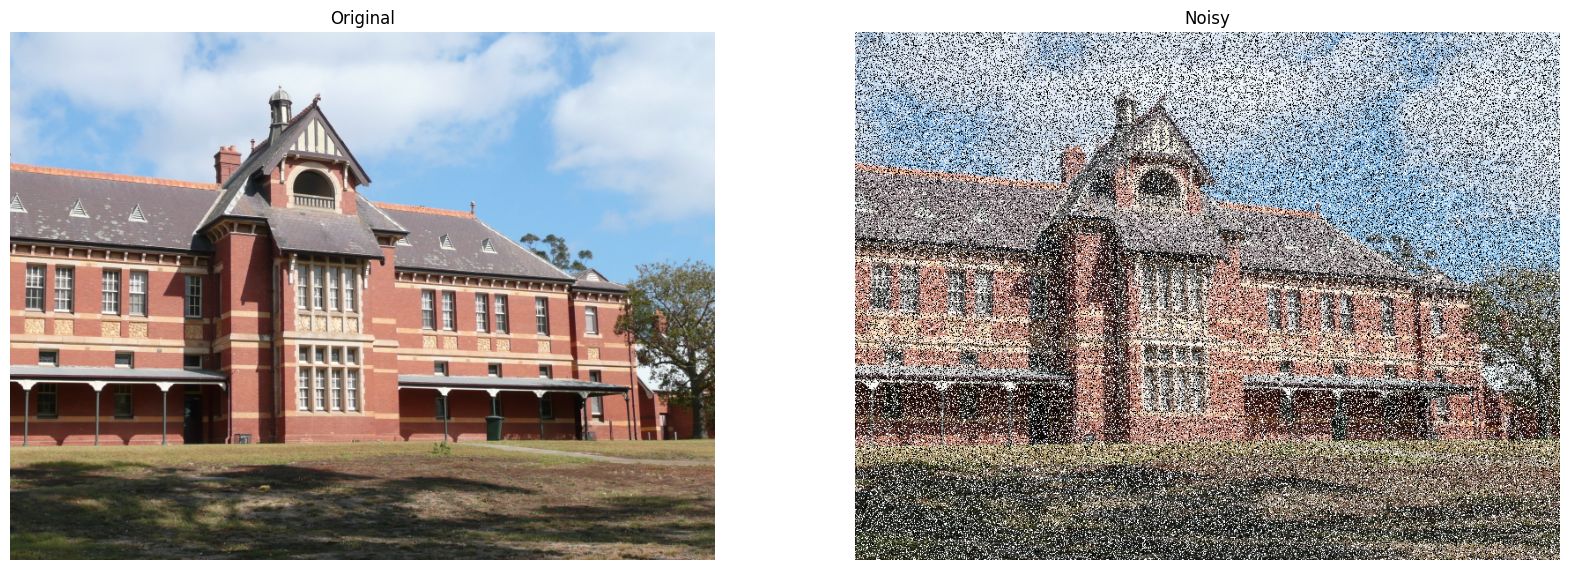

In [6]:
# TODO: Create a figure with two subplots side by side
plt.figure(figsize=(20, 20))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_noise, cv2.COLOR_BGR2RGB))
plt.title("Noisy")
plt.axis("off")
plt.show()


# SECTION 4: Histogram Analysis


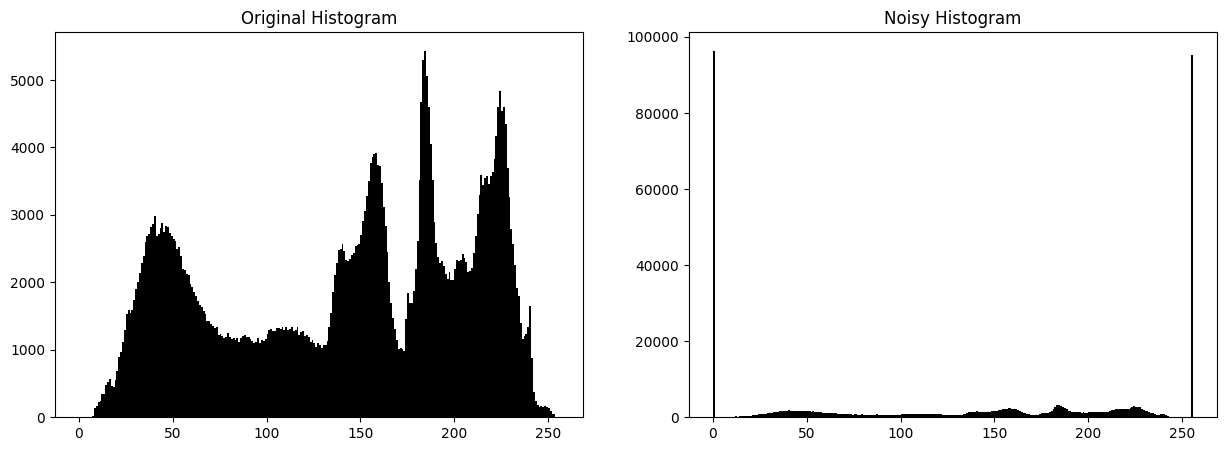

In [7]:
# TODO: Plot histograms of original and noisy images
plt.figure(figsize=(15, 5))
img_gray_hist = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_noise_gray_hist = cv2.cvtColor(img_noise, cv2.COLOR_BGR2GRAY)
plt.subplot(1, 2, 1)
plt.hist(img_gray_hist.ravel(), bins=256, range=[0, 256], color="black")
plt.title("Original Histogram")
plt.subplot(1, 2, 2)
plt.hist(img_noise_gray_hist.ravel(), bins=256, range=[0, 256], color="black")
plt.title("Noisy Histogram")
plt.show()


# SECTION 5: Frequency Domain Analysis


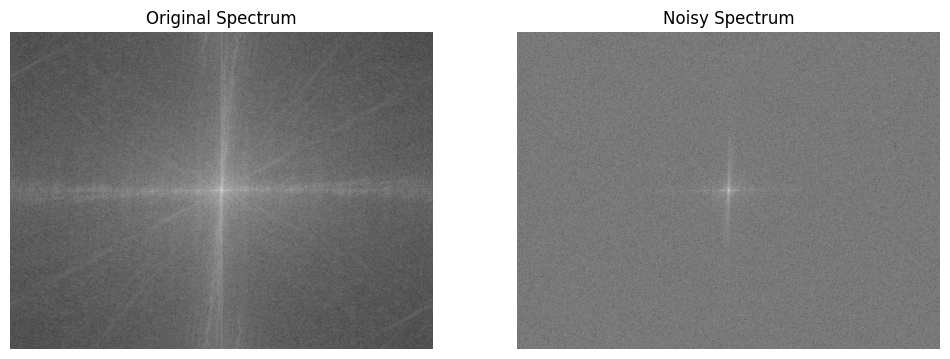

In [8]:
# TODO: Compute and display Fourier transform of both images
# Hint:
# 1. Convert image to grayscale
# 2. Apply 2D FFT using np.fft.fft2()
# 3. Shift zero frequency to center using np.fft.fftshift()
# 4. Compute magnitude spectrum using np.log(np.abs(...) + 1)

img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_noise_gray = cv2.cvtColor(img_noise, cv2.COLOR_BGR2GRAY)

# YOUR CODE HERE
f = np.fft.fft2(img_gray)
fshift = np.fft.fftshift(f)
magnitude_spectrum = np.log(np.abs(fshift) + 1)

f2 = np.fft.fft2(img_noise_gray)
fshift2 = np.fft.fftshift(f2)
magnitude_spectrum2 = np.log(np.abs(fshift2) + 1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Original Spectrum")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum2, cmap="gray")
plt.title("Noisy Spectrum")
plt.axis("off")
plt.show()


# SECTION 6: Denoising - Mean Filter


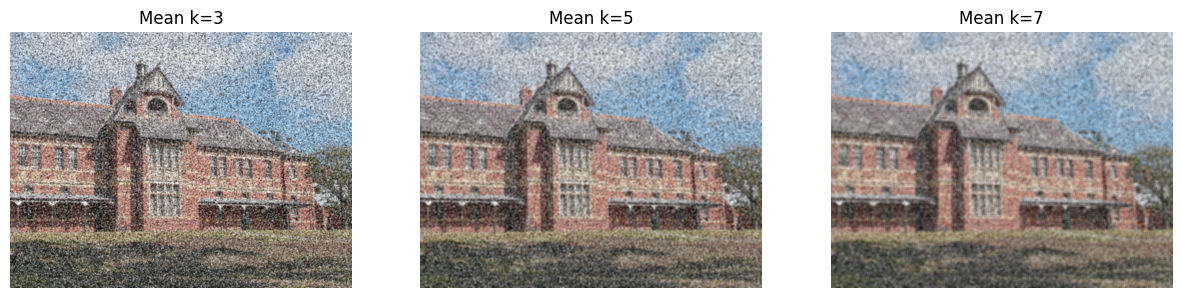

In [9]:
# TODO: Apply mean filter 

kernel_sizes = [3, 5, 7]
denoised_mean = {}

for k in kernel_sizes:
    denoised_mean[k] = cv2.blur(img_noise, (k, k))

# TODO: Display results for different kernel sizes
plt.figure(figsize=(15, 5))
for i, k in enumerate(kernel_sizes, start=1):
    plt.subplot(1, len(kernel_sizes), i)
    plt.imshow(cv2.cvtColor(denoised_mean[k], cv2.COLOR_BGR2RGB))
    plt.title(f"Mean k={k}")
    plt.axis("off")
plt.show()


# SECTION 7: Denoising - Gaussian Filter


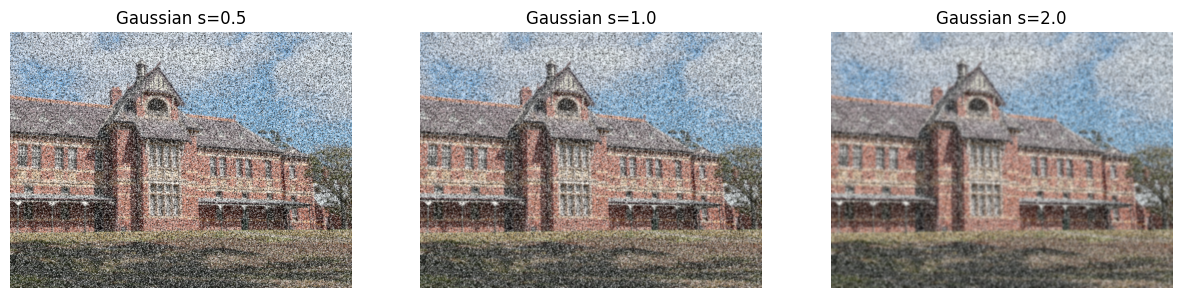

In [10]:
# TODO: Apply Gaussian filter 
# Experiment with different sigma values: 0.5, 1.0, 2.0

sigma_values = [0.5, 1.0, 2.0]
denoised_gaussian = {}

for sigma in sigma_values:
    denoised_gaussian[sigma] = cv2.GaussianBlur(img_noise, (0, 0), sigmaX=sigma, sigmaY=sigma)

# TODO: Display results
plt.figure(figsize=(15, 5))
for i, sigma in enumerate(sigma_values, start=1):
    plt.subplot(1, len(sigma_values), i)
    plt.imshow(cv2.cvtColor(denoised_gaussian[sigma], cv2.COLOR_BGR2RGB))
    plt.title(f"Gaussian s={sigma}")
    plt.axis("off")
plt.show()


# SECTION 8: Denoising - Median Filter


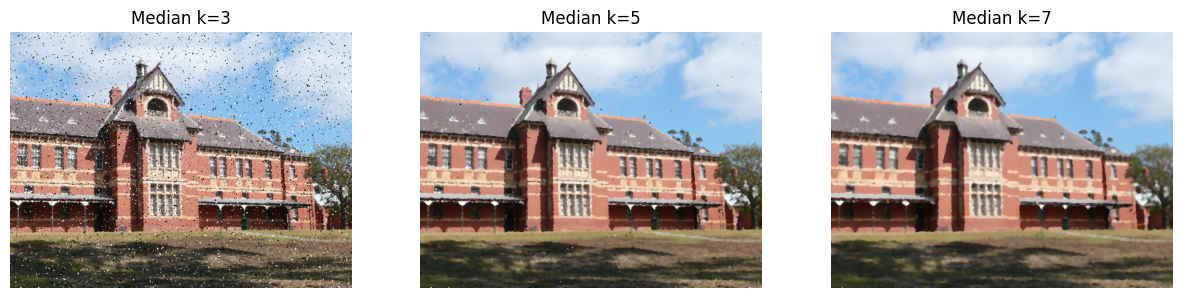

In [11]:
# TODO: Apply median filter using 
# Experiment with kernel sizes: 3, 5, 7

kernel_sizes_med = [3, 5, 7]
denoised_median = {}

for k in kernel_sizes_med:
    denoised_median[k] = cv2.medianBlur(img_noise, k)

# TODO: Display results and compare with mean/Gaussian filters
plt.figure(figsize=(15, 5))
for i, k in enumerate(kernel_sizes_med, start=1):
    plt.subplot(1, len(kernel_sizes_med), i)
    plt.imshow(cv2.cvtColor(denoised_median[k], cv2.COLOR_BGR2RGB))
    plt.title(f"Median k={k}")
    plt.axis("off")
plt.show()


# SECTION 9: Performance Evaluation - PSNR


In [12]:
# TODO: Implement PSNR (Peak Signal-to-Noise Ratio) function

def calculate_psnr(original, denoised):
    """
    Calculate PSNR between original and denoised images.
    
    Args:
        original: original image
        denoised: denoised image
    
    Returns:
        psnr: PSNR value in dB
    """
    if original is None or denoised is None:
        return float("nan")
    original_f = original.astype(np.float64)
    denoised_f = denoised.astype(np.float64)
    mse = np.mean((original_f - denoised_f) ** 2)
    if mse == 0:
        return float("inf")
    return 20 * np.log10(255.0) - 10 * np.log10(mse)


# TODO: Calculate PSNR for all denoised results and print as a table
print("\n" + "="*60)
print("PSNR Results (dB) - Higher is better")
print("="*60)

psnr_rows = []

for k in kernel_sizes:
    psnr_rows.append(("Mean", f"k={k}", calculate_psnr(img, denoised_mean[k])))

for sigma in sigma_values:
    psnr_rows.append(("Gaussian", f"sigma={sigma}", calculate_psnr(img, denoised_gaussian[sigma])))

for k in kernel_sizes_med:
    psnr_rows.append(("Median", f"k={k}", calculate_psnr(img, denoised_median[k])))

print("{:<15} {:<15} {:<10}".format("Method", "Params", "PSNR"))
print("-"*60)
for method, params, value in psnr_rows:
    if np.isinf(value):
        value_str = "inf"
    else:
        value_str = f"{value:.2f}"
    print("{:<15} {:<15} {:<10}".format(method, params, value_str))


PSNR Results (dB) - Higher is better
Method          Params          PSNR      
------------------------------------------------------------
Mean            k=3             15.53     
Mean            k=5             16.76     
Mean            k=7             16.96     
Gaussian        sigma=0.5       11.99     
Gaussian        sigma=1.0       16.13     
Gaussian        sigma=2.0       17.12     
Median          k=3             17.98     
Median          k=5             23.72     
Median          k=7             23.05     



# SECTION 10: Performance Evaluation - SSIM


In [13]:
# TODO: Implement or use SSIM (Structural Similarity Index)

from skimage.metrics import structural_similarity as ssim

def calculate_ssim(original, denoised):
    """
    Calculate SSIM between original and denoised images.
    
    Args:
        original: original image
        denoised: denoised image
    
    Returns:
        ssim_value: SSIM value (between -1 and 1, closer to 1 is better)
    """
    if original is None or denoised is None:
        return float("nan")
    original_f = original.astype(np.float64)
    denoised_f = denoised.astype(np.float64)
    if original_f.ndim == 3:
        try:
            return ssim(original_f, denoised_f, channel_axis=-1, data_range=255)
        except TypeError:
            return ssim(original_f, denoised_f, multichannel=True, data_range=255)
    return ssim(original_f, denoised_f, data_range=255)


# TODO: Calculate SSIM for all denoised results
print("\n" + "="*60)
print("SSIM Results - Higher is better (max = 1.0)")
print("="*60)

ssim_rows = []

for k in kernel_sizes:
    ssim_rows.append(("Mean", f"k={k}", calculate_ssim(img, denoised_mean[k])))

for sigma in sigma_values:
    ssim_rows.append(("Gaussian", f"sigma={sigma}", calculate_ssim(img, denoised_gaussian[sigma])))

for k in kernel_sizes_med:
    ssim_rows.append(("Median", f"k={k}", calculate_ssim(img, denoised_median[k])))

print("{:<15} {:<15} {:<10}".format("Method", "Params", "SSIM"))
print("-"*60)
for method, params, value in ssim_rows:
    if np.isnan(value):
        value_str = "nan"
    else:
        value_str = f"{value:.4f}"
    print("{:<15} {:<15} {:<10}".format(method, params, value_str))

C:\Users\ROG\AppData\Roaming\Python\Python311\site-packages\skimage\metrics\_structural_similarity.py:4: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.4)
  from scipy.ndimage import uniform_filter



SSIM Results - Higher is better (max = 1.0)
Method          Params          SSIM      
------------------------------------------------------------
Mean            k=3             0.2141    
Mean            k=5             0.3032    
Mean            k=7             0.3681    
Gaussian        sigma=0.5       0.1156    
Gaussian        sigma=1.0       0.2542    
Gaussian        sigma=2.0       0.4137    
Median          k=3             0.5155    
Median          k=5             0.7784    
Median          k=7             0.7349    



# SECTION 11: Frequency Domain Filtering


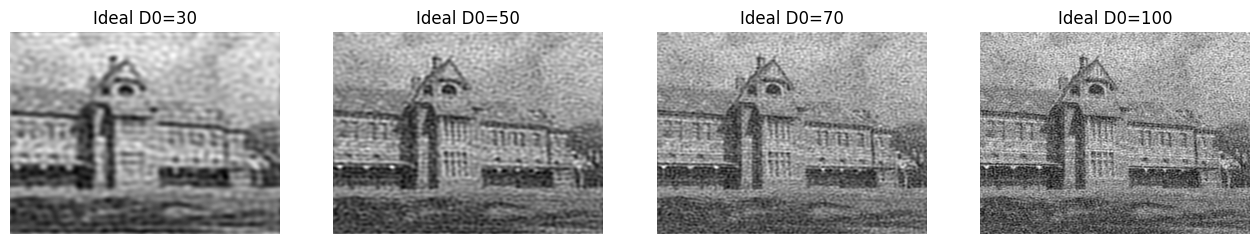

In [14]:
# TODO: Implement ideal low-pass filter in frequency domain

def ideal_lowpass_filter(image, D0):
    """
    Apply ideal low-pass filter in frequency domain.
    
    Args:
        image: input image (grayscale)
        D0: cutoff radius
    
    Returns:
        filtered: filtered image
    """
    if image is None:
        return None
    img = image.astype(np.float32)
    rows, cols = img.shape
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    u = np.arange(rows) - rows / 2.0
    v = np.arange(cols) - cols / 2.0
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U ** 2 + V ** 2)
    H = (D <= D0).astype(np.float32)
    fshift_filtered = fshift * H
    img_back = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
    result = np.real(img_back)
    result = np.clip(result, 0, 255)
    return result.astype(np.uint8)


# TODO: Apply with different cutoff radii: 30, 50, 70, 100
cutoff_radii = [30, 50, 70, 100]
ideal_filtered = {}

for D0 in cutoff_radii:
    ideal_filtered[D0] = ideal_lowpass_filter(img_noise_gray, D0)

plt.figure(figsize=(16, 4))
for i, D0 in enumerate(cutoff_radii, start=1):
    plt.subplot(1, len(cutoff_radii), i)
    plt.imshow(ideal_filtered[D0], cmap="gray")
    plt.title(f"Ideal D0={D0}")
    plt.axis("off")
plt.show()


# SECTION 12: Gaussian Low-Pass Filter in Frequency Domain


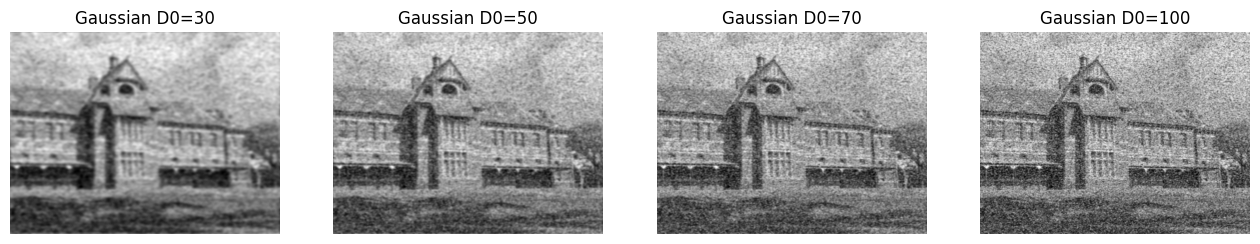

In [15]:
# TODO: Implement Gaussian low-pass filter

def gaussian_lowpass_filter(image, D0):
    """
    Apply Gaussian low-pass filter in frequency domain.
    
    Args:
        image: input image (grayscale)
        D0: cutoff parameter
    
    Returns:
        filtered: filtered image
    """
    if image is None:
        return None
    img = image.astype(np.float32)
    rows, cols = img.shape
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    u = np.arange(rows) - rows / 2.0
    v = np.arange(cols) - cols / 2.0
    V, U = np.meshgrid(v, u)
    D2 = U ** 2 + V ** 2
    H = np.exp(-D2 / (2.0 * (D0 ** 2)))
    fshift_filtered = fshift * H
    img_back = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
    result = np.real(img_back)
    result = np.clip(result, 0, 255)
    return result.astype(np.uint8)

# TODO: Apply with different D0 values and compare
gaussian_filtered = {}

for D0 in cutoff_radii:
    gaussian_filtered[D0] = gaussian_lowpass_filter(img_noise_gray, D0)

plt.figure(figsize=(16, 4))
for i, D0 in enumerate(cutoff_radii, start=1):
    plt.subplot(1, len(cutoff_radii), i)
    plt.imshow(gaussian_filtered[D0], cmap="gray")
    plt.title(f"Gaussian D0={D0}")
    plt.axis("off")
plt.show()


# SECTION 13: Wiener Filter


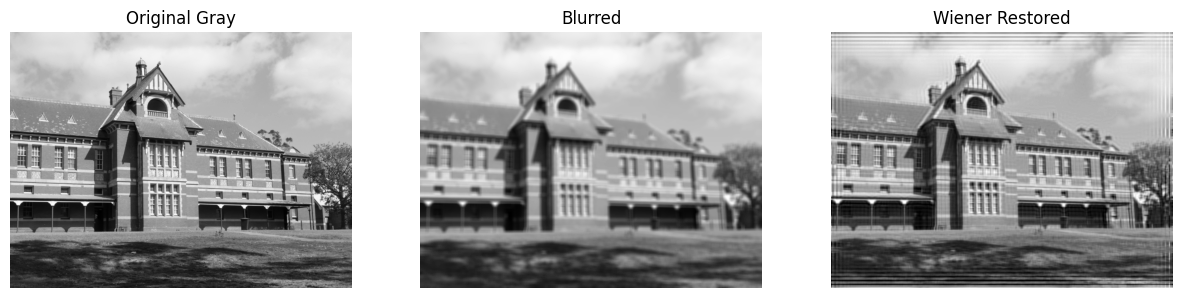

In [16]:
# TODO: Implement Wiener filter for image restoration

def wiener_filter(blurred, psf, K=0.01):
    """
    Apply Wiener filter for image restoration.
    
    Args:
        blurred: blurred/noisy image
        psf: point spread function (degradation function)
        K: noise-to-signal ratio parameter
    
    Returns:
        restored: restored image
    """
    if blurred is None or psf is None:
        return None
    blurred_f = blurred.astype(np.float32)
    psf_f = psf.astype(np.float32)
    H = np.fft.fft2(psf_f, s=blurred_f.shape)
    G = np.fft.fft2(blurred_f)
    H_conj = np.conj(H)
    denom = (np.abs(H) ** 2) + K
    F_hat = (H_conj / denom) * G
    f = np.fft.ifft2(F_hat)
    result = np.real(f)
    result = np.clip(result, 0, 255)
    return result.astype(np.uint8)


# TODO: Create synthetic blur and restore using Wiener filter
psf_size = 9
psf = np.ones((psf_size, psf_size), dtype=np.float32)
psf = psf / psf.sum()
blurred = cv2.filter2D(img_gray, -1, psf)
restored = wiener_filter(blurred, psf, K=0.01)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_gray, cmap="gray")
plt.title("Original Gray")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(restored, cmap="gray")
plt.title("Wiener Restored")
plt.axis("off")
plt.show()


# SECTION 14: Comparative Analysis


In [17]:
# TODO: Create a summary table comparing all denoising methods
# Include: Method name, Parameters, PSNR, SSIM, Computational complexity

results_summary = []
import time

orig_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

for k in kernel_sizes:
    t0 = time.perf_counter()
    out = cv2.blur(img_noise, (k, k))
    t1 = time.perf_counter()
    out_gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
    psnr_val = calculate_psnr(orig_gray, out_gray)
    ssim_val = calculate_ssim(orig_gray, out_gray)
    results_summary.append(("Mean", f"k={k}", psnr_val, ssim_val, (t1 - t0) * 1000))

for sigma in sigma_values:
    t0 = time.perf_counter()
    out = cv2.GaussianBlur(img_noise, (0, 0), sigmaX=sigma, sigmaY=sigma)
    t1 = time.perf_counter()
    out_gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
    psnr_val = calculate_psnr(orig_gray, out_gray)
    ssim_val = calculate_ssim(orig_gray, out_gray)
    results_summary.append(("Gaussian", f"sigma={sigma}", psnr_val, ssim_val, (t1 - t0) * 1000))

for k in kernel_sizes_med:
    t0 = time.perf_counter()
    out = cv2.medianBlur(img_noise, k)
    t1 = time.perf_counter()
    out_gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
    psnr_val = calculate_psnr(orig_gray, out_gray)
    ssim_val = calculate_ssim(orig_gray, out_gray)
    results_summary.append(("Median", f"k={k}", psnr_val, ssim_val, (t1 - t0) * 1000))

for D0 in cutoff_radii:
    t0 = time.perf_counter()
    out = ideal_lowpass_filter(img_noise_gray, D0)
    t1 = time.perf_counter()
    psnr_val = calculate_psnr(orig_gray, out)
    ssim_val = calculate_ssim(orig_gray, out)
    results_summary.append(("Ideal LPF", f"D0={D0}", psnr_val, ssim_val, (t1 - t0) * 1000))

for D0 in cutoff_radii:
    t0 = time.perf_counter()
    out = gaussian_lowpass_filter(img_noise_gray, D0)
    t1 = time.perf_counter()
    psnr_val = calculate_psnr(orig_gray, out)
    ssim_val = calculate_ssim(orig_gray, out)
    results_summary.append(("Gaussian LPF", f"D0={D0}", psnr_val, ssim_val, (t1 - t0) * 1000))

psf_size = 9
psf = np.ones((psf_size, psf_size), dtype=np.float32)
psf = psf / psf.sum()
blurred = cv2.filter2D(orig_gray, -1, psf)
t0 = time.perf_counter()
restored = wiener_filter(blurred, psf, K=0.01)
t1 = time.perf_counter()
psnr_val = calculate_psnr(orig_gray, restored)
ssim_val = calculate_ssim(orig_gray, restored)
results_summary.append(("Wiener", "K=0.01", psnr_val, ssim_val, (t1 - t0) * 1000))

# Display as formatted table
print("\n" + "="*80)
print("{:<20} {:<20} {:<10} {:<10} {:<15}".format(
    "Method", "Parameters", "PSNR(dB)", "SSIM", "Time(ms)"))
print("-"*80)
for method, params, psnr_val, ssim_val, t_ms in results_summary:
    psnr_str = "inf" if np.isinf(psnr_val) else f"{psnr_val:.2f}"
    ssim_str = "nan" if np.isnan(ssim_val) else f"{ssim_val:.4f}"
    print("{:<20} {:<20} {:<10} {:<10} {:<15.2f}".format(
        method, params, psnr_str, ssim_str, t_ms))


Method               Parameters           PSNR(dB)   SSIM       Time(ms)       
--------------------------------------------------------------------------------
Mean                 k=3                  15.84      0.2152     2.22           
Mean                 k=5                  17.14      0.3069     2.67           
Mean                 k=7                  17.35      0.3742     0.88           
Gaussian             sigma=0.5            12.18      0.1154     1.25           
Gaussian             sigma=1.0            16.48      0.2560     1.06           
Gaussian             sigma=2.0            17.53      0.4203     0.94           
Median               k=3                  18.10      0.5077     0.64           
Median               k=5                  23.76      0.7848     1.86           
Median               k=7                  23.09      0.7429     35.22          
Ideal LPF            D0=30                16.98      0.4929     35.45          
Ideal LPF            D0=50            


# SECTION 15: Bonus - Adaptive Median Filter


In [18]:
# TODO: Implement adaptive median filter for better noise removal

def adaptive_median_filter(image, max_kernel_size=7):
    """
    Adaptive median filter that adjusts window size.
    
    Args:
        image: input noisy image
        max_kernel_size: maximum window size to try
    
    Returns:
        filtered: filtered image
    """
    if image is None:
        return None
    if max_kernel_size % 2 == 0:
        max_kernel_size += 1
    if image.ndim == 2:
        img = image
        pad = max_kernel_size // 2
        padded = np.pad(img, pad, mode="reflect")
        h, w = img.shape
        out = np.empty_like(img)
        for i in range(h):
            for j in range(w):
                k = 3
                while True:
                    r = k // 2
                    window = padded[i + pad - r:i + pad + r + 1, j + pad - r:j + pad + r + 1]
                    zmin = window.min()
                    zmax = window.max()
                    zmed = np.median(window)
                    A1 = zmed - zmin
                    A2 = zmed - zmax
                    if A1 > 0 and A2 < 0:
                        zxy = img[i, j]
                        B1 = zxy - zmin
                        B2 = zxy - zmax
                        if B1 > 0 and B2 < 0:
                            out[i, j] = zxy
                        else:
                            out[i, j] = zmed
                        break
                    k += 2
                    if k > max_kernel_size:
                        out[i, j] = zmed
                        break
        return out.astype(img.dtype)
    channels = cv2.split(image)
    filtered_channels = [adaptive_median_filter(ch, max_kernel_size) for ch in channels]
    return cv2.merge(filtered_channels)

In [20]:
adaptive_max_k = 7
denoised_adaptive = adaptive_median_filter(img_noise, max_kernel_size=adaptive_max_k)

psnr_rows_adaptive = []
for k in kernel_sizes:
    psnr_rows_adaptive.append(("Mean", f"k={k}", calculate_psnr(img, denoised_mean[k])))
for sigma in sigma_values:
    psnr_rows_adaptive.append(("Gaussian", f"sigma={sigma}", calculate_psnr(img, denoised_gaussian[sigma])))
for k in kernel_sizes_med:
    psnr_rows_adaptive.append(("Median", f"k={k}", calculate_psnr(img, denoised_median[k])))
psnr_rows_adaptive.append(("Adaptive Median", f"max_k={adaptive_max_k}", calculate_psnr(img, denoised_adaptive)))

print("\n" + "="*60)
print("PSNR Results (dB) - Including Adaptive Median")
print("="*60)
print("{:<18} {:<18} {:<10}".format("Method", "Params", "PSNR"))
print("-"*60)
for method, params, value in psnr_rows_adaptive:
    if np.isinf(value):
        value_str = "inf"
    else:
        value_str = f"{value:.2f}"
    print("{:<18} {:<18} {:<10}".format(method, params, value_str))

ssim_rows_adaptive = []
for k in kernel_sizes:
    ssim_rows_adaptive.append(("Mean", f"k={k}", calculate_ssim(img, denoised_mean[k])))
for sigma in sigma_values:
    ssim_rows_adaptive.append(("Gaussian", f"sigma={sigma}", calculate_ssim(img, denoised_gaussian[sigma])))
for k in kernel_sizes_med:
    ssim_rows_adaptive.append(("Median", f"k={k}", calculate_ssim(img, denoised_median[k])))
ssim_rows_adaptive.append(("Adaptive Median", f"max_k={adaptive_max_k}", calculate_ssim(img, denoised_adaptive)))

print("\n" + "="*60)
print("SSIM Results - Including Adaptive Median")
print("="*60)
print("{:<18} {:<18} {:<10}".format("Method", "Params", "SSIM"))
print("-"*60)
for method, params, value in ssim_rows_adaptive:
    if np.isnan(value):
        value_str = "nan"
    else:
        value_str = f"{value:.4f}"
    print("{:<18} {:<18} {:<10}".format(method, params, value_str))

C:\Users\ROG\AppData\Local\Temp\ipykernel_7780\1292709570.py:38: RuntimeWarning: overflow encountered in scalar subtract
  B2 = zxy - zmax



PSNR Results (dB) - Including Adaptive Median
Method             Params             PSNR      
------------------------------------------------------------
Mean               k=3                15.53     
Mean               k=5                16.76     
Mean               k=7                16.96     
Gaussian           sigma=0.5          11.99     
Gaussian           sigma=1.0          16.13     
Gaussian           sigma=2.0          17.12     
Median             k=3                17.98     
Median             k=5                23.72     
Median             k=7                23.05     
Adaptive Median    max_k=7            25.09     

SSIM Results - Including Adaptive Median
Method             Params             SSIM      
------------------------------------------------------------
Mean               k=3                0.2141    
Mean               k=5                0.3032    
Mean               k=7                0.3681    
Gaussian           sigma=0.5          0.1156    
Gauss


# SECTION 16: Final Visualization - Best Results


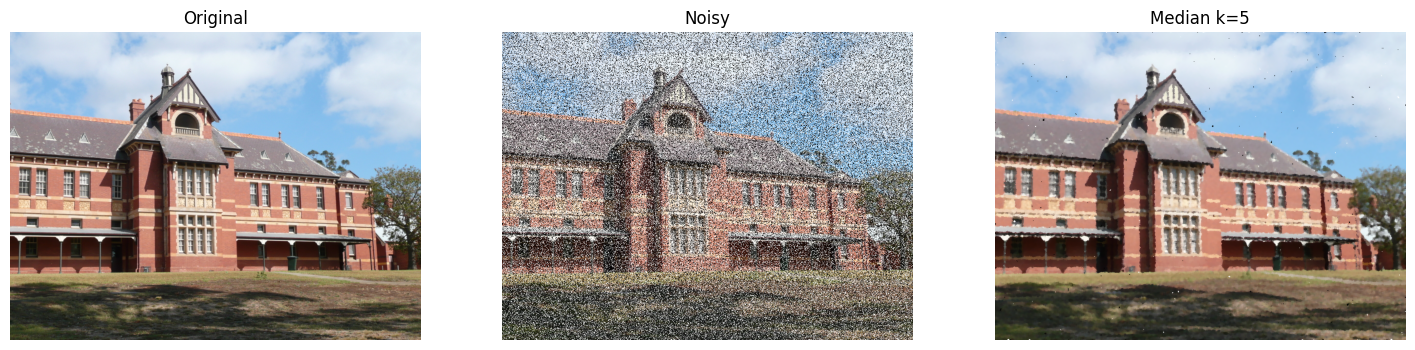

In [19]:
# TODO: Display original, noisy, and best denoised result side by side

candidates = []

for k in kernel_sizes:
    candidates.append((calculate_psnr(img, denoised_mean[k]), denoised_mean[k], f"Mean k={k}"))

for sigma in sigma_values:
    candidates.append((calculate_psnr(img, denoised_gaussian[sigma]), denoised_gaussian[sigma], f"Gaussian s={sigma}"))

for k in kernel_sizes_med:
    candidates.append((calculate_psnr(img, denoised_median[k]), denoised_median[k], f"Median k={k}"))

best = max(candidates, key=lambda x: x[0])
best_denoised = best[1]
best_title = best[2]

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_noise, cv2.COLOR_BGR2RGB))
plt.title("Noisy")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(best_denoised, cv2.COLOR_BGR2RGB))
plt.title(best_title)
plt.axis("off")
plt.show()

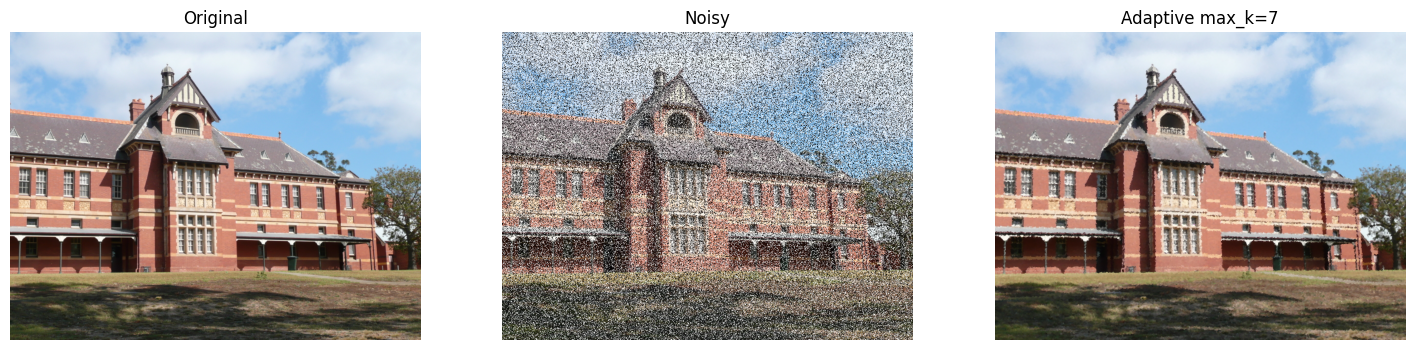

In [21]:
candidates_with_adaptive = []

for k in kernel_sizes:
    candidates_with_adaptive.append((calculate_psnr(img, denoised_mean[k]), denoised_mean[k], f"Mean k={k}"))

for sigma in sigma_values:
    candidates_with_adaptive.append((calculate_psnr(img, denoised_gaussian[sigma]), denoised_gaussian[sigma], f"Gaussian s={sigma}"))

for k in kernel_sizes_med:
    candidates_with_adaptive.append((calculate_psnr(img, denoised_median[k]), denoised_median[k], f"Median k={k}"))

candidates_with_adaptive.append((calculate_psnr(img, denoised_adaptive), denoised_adaptive, f"Adaptive max_k={adaptive_max_k}"))

best = max(candidates_with_adaptive, key=lambda x: x[0])
best_denoised = best[1]
best_title = best[2]

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_noise, cv2.COLOR_BGR2RGB))
plt.title("Noisy")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(best_denoised, cv2.COLOR_BGR2RGB))
plt.title(best_title)
plt.axis("off")
plt.show()